# Ring trap: point-resolution convergence and time-per-step benchmark

This notebook performes simulations of the ring trap with analytically known potential minimum at several point-trap resolutions.

At each resolution it consideres two questions:

1. **Equilibrium convergence:** How closely does the final time-averaged one-ion
   position approach the analytical reference
   $\mathbf r_{\mathrm{analytic}}=(0,0,100)\,\mu\mathrm m$.
2. **Computational scaling:** How does the wall-clock time per MD step
   depend on the number of active point elements, determined by the `resolution`
   parameter.

## Timing protocol

For each point trap (built once per resolution), execute two independent
simulations from the same initial condition and with identical trap/cooling/dump
configuration:

- `pl.evolve(1)` — short run, wall-clock duration $T_1$.
- `pl.evolve(TOTAL_STEPS + 1)` — long run, duration $T_{N+1}$,
  *also used to obtain the equilibrium trajectory*.

The reported timing metric is

$$
 t_{\mathrm{step}} = \frac{T_{N+1}-T_1}{N},\qquad N=\mathrm{TOTAL\_STEPS}.
$$

This subtracts approximate initialization/launch overhead, but still includes
periodic trajectory-writing overhead and any step-dependent work. 

`sn.point_trap_design()` returns only the point centers
inside the electrode boundary. The notebook counts the active elements in the
returned `trap` object, matching the terms evaluated by `sn.point_trap()`. The
count excludes the unoccupied sampling lattice and zero-voltage electrodes.
Both the accuracy and time-scaling plots use active point count as their
horizontal coordinate, annotating the corresponding `res`.

You can change `AVERAGE_LAST_STEPS` later and rerun the analysis/plot cells
without running LAMMPS again: set `RUN_SIMULATIONS = False` to load saved data.

## 1. Initialization

In [16]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.constants as ct
from IPython.display import display

import sion as sn
import sion.pylion as pl

# Resolution sweep
RESOLUTIONS = [10,20,30,40,50,60]

# N integration steps for the timing difference; the LONG run uses N+1 steps.
TOTAL_STEPS = 10_000
DUMP_EVERY = 10
AVERAGE_LAST_STEPS = 1_00  # final window in simulation STEPS, not frames

# False: skip both timing runs, reload saved trajectory and timing CSV instead.
RUN_SIMULATIONS = False
SHOW_ELECTRODE_DESIGN = False

# Pre-configured physical parameters
ANALYTIC_POSITION_UM = np.array([0.0, 0.0, 100.0])
INITIAL_POSITION_UM = np.array([3.0, -5.0, 95.0])
VRF_V = 120.0
RF_FREQUENCY_HZ = 30e6
OMEGA = 2.0 * np.pi * RF_FREQUENCY_HZ
ION_MASS_AMU = 40
ION_CHARGE_E = 1
LANGEVIN_TEMPERATURE_K = 0
LANGEVIN_DAMPING = 1e-7

OUTPUT_DIR = Path.cwd() / 'supplementary' / 'ring_resolution_convergence_output'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TIMING_CSV = OUTPUT_DIR / 'ring_point_timing.csv'

assert len(RESOLUTIONS) == len(set(RESOLUTIONS))
assert all(isinstance(res, int) and res > 0 for res in RESOLUTIONS)
assert isinstance(TOTAL_STEPS, int) and TOTAL_STEPS > 1
assert isinstance(DUMP_EVERY, int) and DUMP_EVERY > 0
assert 4 * DUMP_EVERY <= AVERAGE_LAST_STEPS <= TOTAL_STEPS
print('Output directory:', OUTPUT_DIR)
print(f'Short run = 1 step; long run = {TOTAL_STEPS+1:,} steps; '
      f'sampling every {DUMP_EVERY} steps; last-window mean = {AVERAGE_LAST_STEPS:,} steps')

Output directory: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\ring_resolution_convergence_output
Short run = 1 step; long run = 10,001 steps; sampling every 10 steps; last-window mean = 100 steps


## 2. Geometry and simulation functions

Initiailizes theoretical ring geometry, which should confine ions at 100 um height. Defines functions, initializing the simulation.

In [17]:
# Theoretical ring geometry 
sc = np.sqrt(3.0 / (4.0 * np.sin(np.pi / 12.0)**2) - 1.0)
r_inner_m = 100.0 / np.sqrt(2.0) * 1e-6
r_outer_m = 100.0 * sc * 1e-6
scale_m = 1.5 * r_outer_m


def ring_boundary(electrode_index, xy):
    rho_sq = xy[0]**2 + xy[1]**2
    return electrode_index == 0 and r_inner_m**2 < rho_sq < r_outer_m**2


def dump_path_for(res):
    return OUTPUT_DIR / f'positions_ring_res{res}.txt'


def design_ring_trap(res):
    """Build geometry once and reuse the returned trap for both timing runs."""
    _, trap = sn.point_trap_design(
        frequencies=[OMEGA],
        rf_voltages=[VRF_V],
        dc_voltages=[],
        boundaries=ring_boundary,
        scale=scale_m,
        resolution=res,
        need_plot=SHOW_ELECTRODE_DESIGN,
        need_coordinates=True,
    )
    return trap


def count_active_trap_points(trap):
    """Count only represented points with a nonzero applied voltage.

    Current SION trap layout (as constructed by point_trap_design):
      trap[0] -> RF electrodes: [omega, voltage, areas, centers]
      trap[1] -> DC electrodes: [voltage, areas, centers]

    point_trap() sums terms for each area/center pair, unless voltage == 0.
    Because circle_packaging() has already filtered the boundary, no empty
    lattice/grid points are counted. This is **not** len(System.electrodes)
    or the nominal resolution parameter.
    """
    nrf = 0
    ndc = 0
    for electrode in trap[0]:
        if float(electrode[1]) != 0.0:
            assert len(electrode[2]) == len(electrode[3]), 'RF areas/centers mismatch'
            nrf += len(electrode[2])
    for electrode in trap[1]:
        if float(electrode[0]) != 0.0:
            assert len(electrode[1]) == len(electrode[2]), 'DC areas/centers mismatch'
            ndc += len(electrode[1])
    if nrf + ndc <= 0:
        raise ValueError('No driven electrode points were produced. Check geometry.')
    return nrf, ndc, nrf + ndc


def execute_ring_run(res, trap, steps, *, run_kind):
    """Construct one fresh LAMMPS simulation and time its execute() call.

    The short and long runs use the same commands except the evolve length
    and the output filename. Including dump in both gives the same command
    configuration; the long-run I/O overhead remains in the timing metric.
    """
    if run_kind not in {'short', 'long'}:
        raise ValueError('run_kind must be short or long')
    dump_file = (dump_path_for(res) if run_kind == 'long'
                 else OUTPUT_DIR / f'positions_ring_res{res}_short.txt')
    if dump_file.exists():
        dump_file.unlink()  # avoid stale/appended dump frames

    positions = sn.ions_in_order((INITIAL_POSITION_UM * 1e-6).tolist(), 1, 0)
    simulation_name = str(OUTPUT_DIR / f'RingSimulation_res{res}_{run_kind}')
    sim = pl.Simulation(simulation_name)
    sim.append(pl.placeions(
        {'mass': ION_MASS_AMU, 'charge': ION_CHARGE_E}, positions
    ))
    sim.append(sn.point_trap(trap))
    sim.append(pl.langevinbath(LANGEVIN_TEMPERATURE_K, LANGEVIN_DAMPING))
    sim.append(pl.dump(str(dump_file), variables=['x', 'y', 'z'], steps=DUMP_EVERY))
    sim.append(pl.evolve(steps))

    started = time.perf_counter()
    sim.execute()
    elapsed_s = time.perf_counter() - started

    if run_kind == 'short':
        # Short run is only a timing baseline; its trajectory is not analyzed.
        dump_file.unlink(missing_ok=True)
    elif not dump_file.exists():
        raise FileNotFoundError(f'Long run produced no dump file: {dump_file}')
    return elapsed_s


print(f'Ring inner radius: {r_inner_m*1e6:.3f} µm')
print(f'Ring outer radius: {r_outer_m*1e6:.3f} µm')

Ring inner radius: 70.711 µm
Ring outer radius: 319.314 µm


## 3. Simulation benchmark

Performs the benchmarking protocol.  
**Long run WARNING: took 4 hours for me**

`sn.point_trap_design()` is called once per resolution. Geometry generation is
excluded from the timed `sim.execute()` call. LAMMPS initialization, parsing,
launch, integration, and output are included. The two timing runs use fresh
simulations and identical physical settings. The **long run** supplies the
trajectory for the equilibrium convergence test.

`(time_long - time_short) / TOTAL_STEPS` is evaluated separately at each actual
number of active points. CSV results and dumps are saved so later analysis can
be rerun without re-simulating.

In [18]:
if RUN_SIMULATIONS:
    timing_records = []
    for res in RESOLUTIONS:
        print(f'\nPreparing ring res={res} ...', flush=True)
        t_design_0 = time.perf_counter()
        trap = design_ring_trap(res)
        design_s = time.perf_counter() - t_design_0
        nrf, ndc, npts = count_active_trap_points(trap)
        print(f'  Active points: {npts:,} ({nrf:,} RF, {ndc:,} DC)', flush=True)

        t1 = execute_ring_run(res, trap, 1, run_kind='short')
        print(f'  1 step: {t1:.3f} s', flush=True)
        tlong = execute_ring_run(res, trap, TOTAL_STEPS + 1, run_kind='long')
        print(f'  {TOTAL_STEPS+1:,} steps: {tlong:.3f} s', flush=True)

        delta_t = tlong - t1
        if delta_t <= 0:
            raise RuntimeError(
                f'Invalid timing at res={res}: long run {tlong:.3f}s <= '
                f'short run {t1:.3f}s. Increase TOTAL_STEPS.'
            )
        t_step = delta_t / TOTAL_STEPS
        timing_records.append({
            'resolution': res,
            'n_rf_points': nrf,
            'n_dc_points': ndc,
            'n_active_points': npts,
            'design_time_s': design_s,
            'short_steps': 1,
            'long_steps': TOTAL_STEPS + 1,
            't_short_s': t1,
            't_long_s': tlong,
            't_difference_s': delta_t,
            'time_per_step_s': t_step,
            'time_per_step_ms': 1e3 * t_step,
            'steps_per_s': 1 / t_step,
        })
        print(f'  Estimated time/step: {1e3*t_step:.5f} ms', flush=True)

    timing_results = pd.DataFrame(timing_records).sort_values('resolution').reset_index(drop=True)
    timing_results.to_csv(TIMING_CSV, index=False)
else:
    if not TIMING_CSV.exists():
        raise FileNotFoundError(
            f'Missing saved timing summary: {TIMING_CSV}. '
            'Run the simulations once with RUN_SIMULATIONS=True.'
        )
    timing_results = pd.read_csv(TIMING_CSV)
    missing = sorted(set(RESOLUTIONS) - set(timing_results['resolution']))
    if missing:
        raise ValueError(f'No saved timing / point counts for resolutions {missing}')
    timing_results = timing_results[
        timing_results['resolution'].isin(RESOLUTIONS)
    ].sort_values('resolution').reset_index(drop=True)
    print('Simulation skipped; loaded existing trajectories and timing results.')

display(timing_results[[
    'resolution', 'n_active_points', 't_short_s', 't_long_s',
    'time_per_step_ms', 'steps_per_s', 'design_time_s'
]].round(6))
print('Timing CSV:', TIMING_CSV)

Simulation skipped; loaded existing trajectories and timing results.


,resolution,n_active_points,t_short_s,t_long_s,time_per_step_ms,steps_per_s,design_time_s
0,10,162,0.296567,50.498897,5.020233,199.193945,0.002476
1,20,636,0.393452,197.586851,19.719340,50.711637,0.004345
2,30,1434,0.418896,448.118104,44.769921,22.336425,0.009114
3,40,2526,0.652294,843.148487,84.249619,11.869490,0.038224
4,50,3906,0.666235,1252.381307,125.171507,7.989039,0.029195
5,60,5604,0.845978,1864.440148,186.359417,5.365975,0.035836


Timing CSV: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\ring_resolution_convergence_output\ring_point_timing.csv


## 4. Equilibrium positions

For each resolution the estimated equilibrium is the arithmetic mean of the
last `AVERAGE_LAST_STEPS` simulation steps, selecting the corresponding saved
frames. This is preferable to using a single final snapshot when RF micromotion
or residual secular motion is present.

The **window drift** is the 3D distance between the mean of the first half and
the mean of the second half of the selected frames. A large drift signals that
the run or averaging window may not yet describe a stationary trajectory.
The **RMS motion** measures fluctuations about the window mean. it is not a
statistical confidence interval or a discretization-error estimate.

In [19]:
def load_ring_trajectory(res):
    """Read the saved one-ion trajectory; return (step numbers, positions in µm)."""
    path = dump_path_for(res)
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {path}. Run the simulation cell first, or check OUTPUT_DIR.'
        )

    stored_steps, coordinates_m = pl.readdump(str(path))
    coordinates_m = np.asarray(coordinates_m, dtype=float)
    if coordinates_m.ndim != 3 or coordinates_m.shape[1:] != (1, 3):
        raise ValueError(
            f'Unexpected trajectory shape at res={res}: {coordinates_m.shape}; '
            'expected (frames, 1 ion, 3 coordinates).'
        )

    try:
        steps = np.asarray(stored_steps, dtype=float).reshape(-1)
        if (steps.size != coordinates_m.shape[0]
                or not np.all(np.isfinite(steps))
                or np.any(np.diff(steps) <= 0)):
            raise ValueError('Invalid dump timestep metadata')
    except (ValueError, TypeError):
        steps = np.arange(1, coordinates_m.shape[0] + 1) * DUMP_EVERY

    positions_um = coordinates_m[:, 0, :] * 1e6
    if not np.all(np.isfinite(positions_um)):
        raise ValueError(f'Non-finite coordinates at res={res}')
    return steps, positions_um


def analyze_ring_trajectory(res, steps, positions_um, average_last_steps):
    """Calculate the time-averaged equilibrium and convergence diagnostics."""
    if not 0 < average_last_steps <= TOTAL_STEPS:
        raise ValueError('AVERAGE_LAST_STEPS must be between 1 and TOTAL_STEPS')

    mask = steps > (steps[-1] - average_last_steps)
    steady = positions_um[mask]
    if len(steady) < 4:
        raise ValueError(
            f'Only {len(steady)} saved frames in the averaging window for res={res}; '
            'increase AVERAGE_LAST_STEPS or reduce DUMP_EVERY.'
        )

    mean_position = steady.mean(axis=0)
    difference = mean_position - ANALYTIC_POSITION_UM
    half = len(steady) // 2
    mean_first_half = steady[:half].mean(axis=0)
    mean_second_half = steady[half:].mean(axis=0)
    residuals = steady - mean_position

    result = {
        'resolution': res,
        'mean_x_um': mean_position[0],
        'mean_y_um': mean_position[1],
        'mean_z_um': mean_position[2],
        'error_3d_um': np.linalg.norm(difference),
        'axial_error_um': difference[2],
        'abs_axial_error_um': abs(difference[2]),
        'transverse_error_um': np.linalg.norm(difference[:2]),
        'rms_motion_um': np.sqrt(np.mean(np.sum(residuals**2, axis=1))),
        'window_drift_um': np.linalg.norm(mean_second_half - mean_first_half),
        'n_averaged_frames': len(steady),
        'last_dump_step': steps[-1],
    }
    return result, mask


trajectories = {}
records = []
for res in RESOLUTIONS:
    steps, positions_um = load_ring_trajectory(res)
    result, averaging_mask = analyze_ring_trajectory(
        res, steps, positions_um, AVERAGE_LAST_STEPS
    )
    trajectories[res] = {
        'steps': steps,
        'positions_um': positions_um,
        'averaging_mask': averaging_mask,
    }
    records.append(result)

results = pd.DataFrame(records).sort_values('resolution').reset_index(drop=True)
# Join actual, active simulated point count to convergence metrics.
results = results.merge(
    timing_results[['resolution', 'n_rf_points', 'n_dc_points', 'n_active_points']],
    on='resolution', validate='one_to_one', how='left'
)
if results['n_active_points'].isna().any():
    raise RuntimeError('Point counts missing for some resolutions')
columns = [
    'resolution', 'n_active_points', 'mean_x_um', 'mean_y_um', 'mean_z_um',
    'error_3d_um', 'axial_error_um', 'transverse_error_um',
    'rms_motion_um', 'window_drift_um', 'n_averaged_frames',
]
display(results[columns].round(6))

csv_path = OUTPUT_DIR / 'ring_resolution_convergence.csv'
results.to_csv(csv_path, index=False)
print('Saved summary:', csv_path)

,resolution,n_active_points,mean_x_um,mean_y_um,mean_z_um,error_3d_um,axial_error_um,transverse_error_um,rms_motion_um,window_drift_um,n_averaged_frames
0,10,162,0.000002,-0.000003,94.4820,5.5180,-5.5180,0.000003,0.000004,0.000006,10
1,20,636,0.000005,-0.000009,103.2680,3.2680,3.2680,0.000011,0.000001,0.000001,10
2,30,1434,0.000006,-0.000010,99.8043,0.1957,-0.1957,0.000012,0.000003,0.000005,10
3,40,2526,-0.000005,0.000009,98.1001,1.8999,-1.8999,0.000010,0.000003,0.000006,10
4,50,3906,0.000007,-0.000012,99.6187,0.3813,-0.3813,0.000014,0.000002,0.000004,10
5,60,5604,-0.000001,0.000001,100.5480,0.5480,0.5480,0.000001,0.000003,0.000005,10


Saved summary: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\ring_resolution_convergence_output\ring_resolution_convergence.csv


## 5. Trajectory plots

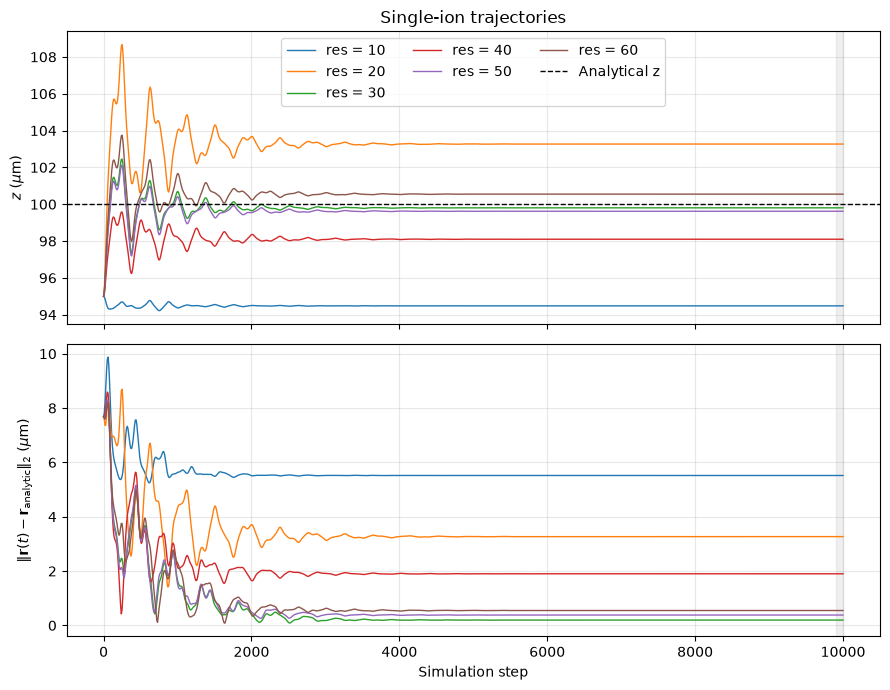

In [23]:
fig, (ax_z, ax_r) = plt.subplots(2, 1, sharex=True, figsize=(9, 7))

for res in RESOLUTIONS:
    entry = trajectories[res]
    steps = entry['steps']
    xyz = entry['positions_um']
    z = xyz[:, 2]
    distance = np.linalg.norm(xyz - ANALYTIC_POSITION_UM, axis=1)
    ax_z.plot(steps, z, label=f'res = {res}', lw=1)
    ax_r.plot(steps, distance, label=f'res = {res}', lw=1)

ax_z.axhline(ANALYTIC_POSITION_UM[2], color='black', linestyle='--',
             linewidth=1, label='Analytical z')
ax_z.set_ylabel(r'$z$ ($\mu$m)')
ax_z.set_title('Single-ion trajectories')
ax_z.legend(ncol=3)

# All runs share TOTAL_STEPS and DUMP_EVERY; shade the final averaging region.
last_step = min(trajectories[res]['steps'][-1] for res in RESOLUTIONS)
for ax in (ax_z, ax_r):
    ax.axvspan(last_step - AVERAGE_LAST_STEPS, last_step,
               color='gray', alpha=0.12, label='Averaging window')
    ax.grid(True, alpha=0.3)

ax_r.set_xlabel('Simulation step')
ax_r.set_ylabel(r'$\|\mathbf{r}(t)-\mathbf{r}_{\mathrm{analytic}}\|_2$ ($\mu$m)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'ring_resolution_trajectories.png', dpi=180)
plt.show()

## 6. Accuracy convergence

This cell plots the accuracy convergence against the number of point electrodes (determined by `res`). The mean averaging-window drift is printed for all resolutions. 

Averaging-window drifts:


,0,1,2,3,4,5
res,10.000000,2.000000e+01,30.000000,40.000000,50.000000,60.000000
"Drifts, um",0.000006,7.061046e-07,0.000005,0.000006,0.000004,0.000005


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


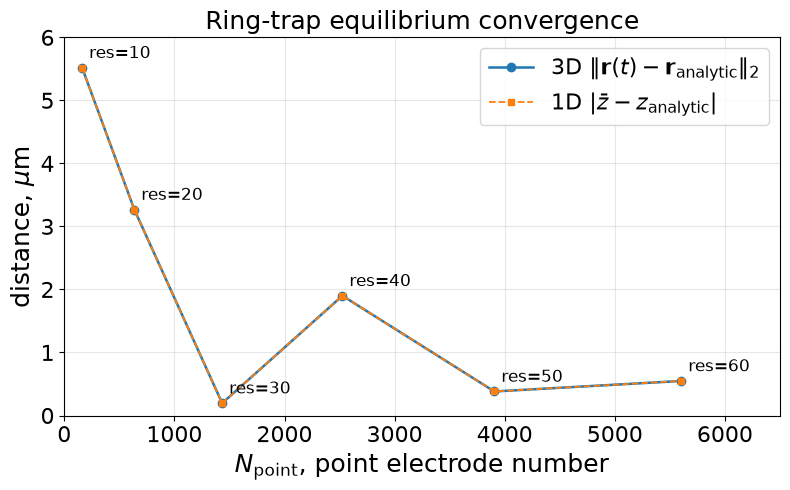

Saved plot: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\ring_resolution_convergence_output\ring_resolution_convergence.eps


In [36]:
plot_data = results.sort_values('n_active_points')
fig, ax = plt.subplots(figsize=(8, 5))
x = plot_data['n_active_points'].to_numpy() 

print(f'Averaging-window drifts:')

avg_win_df = pd.DataFrame({
    "res" : [int(re) for re in RESOLUTIONS],
    "Drifts, um" : plot_data['window_drift_um'],
})

display(avg_win_df.T)

ax.plot(x, plot_data['error_3d_um'], 'o-', lw=1.8, ms=6,
        label=r'3D $\|\mathbf{r}(t)-\mathbf{r}_{\mathrm{analytic}}\|_2$')
ax.plot(x, plot_data['abs_axial_error_um'], 's--', lw=1.3, ms=5,
        label=r'1D $|\bar z-z_\mathrm{analytic}|$')
# ax.plot(x, plot_data['window_drift_um'], 'd:', lw=1.2, ms=5,
#         label='Averaging-window drift (diagnostic)')
for entry in plot_data.itertuples():
    ax.annotate(f'res={entry.resolution}',
                (entry.n_active_points, entry.error_3d_um),
                xytext=(5, 7), textcoords='offset points', fontsize=12)
ax.set_xlabel(r'$N_{\text{point}}$, point electrode number', fontsize=18)
ax.set_ylabel(r'distance, $\mu$m', fontsize=18)
ax.set_title('Ring-trap equilibrium convergence', fontsize=18)
ax.tick_params('both', labelsize=16)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=16)
plt.xlim(0, 6500)
plt.ylim(0, 6)
fig.tight_layout()
plot_path = OUTPUT_DIR / 'ring_resolution_convergence.eps'
fig.savefig(plot_path,dpi=200)
plt.show()
print('Saved plot:', plot_path)

## 7. Time-per-step scaling

Benchmarking plot for time-per-step scaling with the number of point electrodes.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


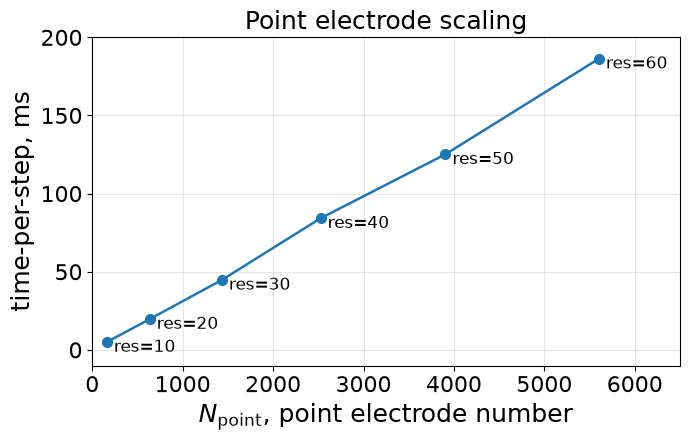

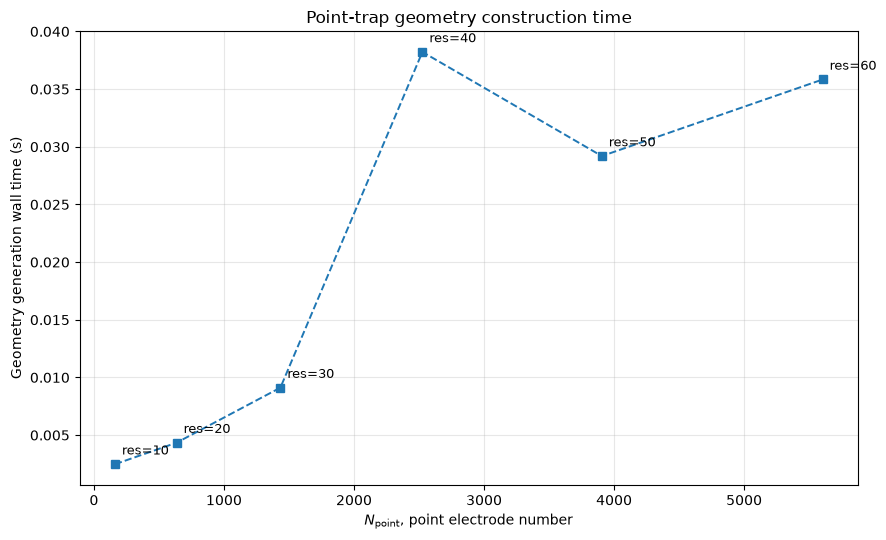

Saved per-step plot: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\ring_resolution_convergence_output\ring_time_per_step_vs_points.eps
Saved design-time plot: c:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\ring_resolution_convergence_output\ring_design_time_vs_points.png


,resolution,n_active_points,error_3d_um,window_drift_um,time_per_step_ms,steps_per_s
0,10,162,5.5180,0.000006,5.020233,199.193945
1,20,636,3.2680,0.000001,19.719340,50.711637
2,30,1434,0.1957,0.000005,44.769921,22.336425
3,40,2526,1.8999,0.000006,84.249619,11.869490
4,50,3906,0.3813,0.000004,125.171507,7.989039
5,60,5604,0.5480,0.000005,186.359417,5.365975


In [44]:
plot_bench = timing_results.sort_values('n_active_points')
x = plot_bench['n_active_points'].to_numpy()
y = plot_bench['time_per_step_ms'].to_numpy()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x, y, 'o-', lw=1.8, ms=7, label='Amortized elapsed time per MD step')
for entry in plot_bench.itertuples():
    ax.annotate(f'res={entry.resolution}',
                (entry.n_active_points, entry.time_per_step_ms),
                xytext=(5, -7), textcoords='offset points', fontsize=12)
ax.set_xlabel(r'$N_{\text{point}}$, point electrode number', fontsize=18)
ax.set_ylabel('time-per-step, ms', fontsize=18)
ax.set_title('Point electrode scaling', fontsize=18)
ax.grid(True, alpha=0.3)
ax.tick_params('both', labelsize=16)
# ax.legend(fontsize=16)
plt.xlim(0, 6500)
plt.ylim(-10, 200)
fig.tight_layout()
bench_plot_path = OUTPUT_DIR / 'ring_time_per_step_vs_points.eps'
fig.savefig(bench_plot_path, dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(x, plot_bench['design_time_s'], 's--', lw=1.4, ms=6)
for entry in plot_bench.itertuples():
    ax.annotate(f'res={entry.resolution}',
                (entry.n_active_points, entry.design_time_s),
                xytext=(5, 7), textcoords='offset points', fontsize=9)
ax.set_xlabel(r'$N_{\text{point}}$, point electrode number')
ax.set_ylabel('Geometry generation wall time (s)')
ax.set_title('Point-trap geometry construction time')
ax.grid(True, alpha=0.3)
fig.tight_layout()
design_plot_path = OUTPUT_DIR / 'ring_design_time_vs_points.png'
fig.savefig(design_plot_path, dpi=200)
plt.show()

print('Saved per-step plot:', bench_plot_path)
print('Saved design-time plot:', design_plot_path)

comparison = results.merge(
    timing_results[['resolution', 'time_per_step_ms', 'steps_per_s']],
    on='resolution', how='left', validate='one_to_one'
)
display(comparison[[
    'resolution', 'n_active_points', 'error_3d_um',
    'window_drift_um', 'time_per_step_ms', 'steps_per_s'
]].round(6))
comparison.to_csv(OUTPUT_DIR / 'ring_accuracy_runtime_comparison.csv', index=False)